# Bài 2 - Neural Network phân lớp MNIST với Train/Validation/Test

**Sinh viên:** Nguyễn Đức Vinh  
**MSSV:** 6451071087

Xây dựng mạng Neural Network cho dữ liệu MNIST; chia tập train thành train/validation theo tỷ lệ 8:2, huấn luyện 5 epoch và đánh giá trên test.

> Chạy lần lượt các cell từ trên xuống dưới trong Google Colab. Mỗi notebook là một bài độc lập.

## 1. Thư viện và thông tin sinh viên

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)

print("Nguyễn Đức Vinh - MSSV: 6451071087")
tf.keras.utils.set_random_seed(42)

Nguyễn Đức Vinh - MSSV: 6451071087


## 2. Đọc dữ liệu MNIST và xem kích thước (câu a, b)

In [2]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()
print("Train images:", train_images.shape)
print("Train labels:", train_labels.shape)
print("Test images:", test_images.shape)
print("Test labels:", test_labels.shape)

Nguyễn Đức Vinh - MSSV: 6451071087
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train images: (60000, 28, 28)
Train labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. Chuẩn hóa và tách tập validation (câu c, d)

In [3]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

X_train, X_val, y_train, y_val = train_test_split(
    train_images, train_labels,
    test_size=0.2, random_state=42, stratify=train_labels
)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)

Nguyễn Đức Vinh - MSSV: 6451071087
X_train: (48000, 28, 28) y_train: (48000,)
X_val: (12000, 28, 28) y_val: (12000,)


## 4. Xây dựng và huấn luyện Neural Network (câu e, f, g)

In [4]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32,
    verbose=1
)

Nguyễn Đức Vinh - MSSV: 6451071087


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9034 - loss: 0.3319 - val_accuracy: 0.9505 - val_loss: 0.1734
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9522 - loss: 0.1609 - val_accuracy: 0.9621 - val_loss: 0.1289
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9629 - loss: 0.1214 - val_accuracy: 0.9669 - val_loss: 0.1097
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9696 - loss: 0.0984 - val_accuracy: 0.9703 - val_loss: 0.0999
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9746 - loss: 0.0820 - val_accuracy: 0.9733 - val_loss: 0.0926


## 5. Biểu đồ Accuracy và Loss (câu h)

Nguyễn Đức Vinh - MSSV: 6451071087


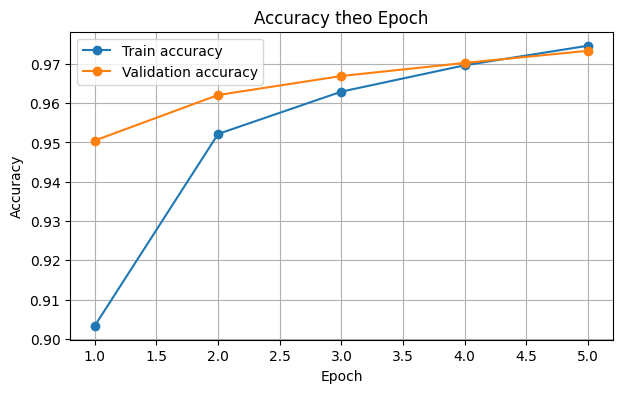

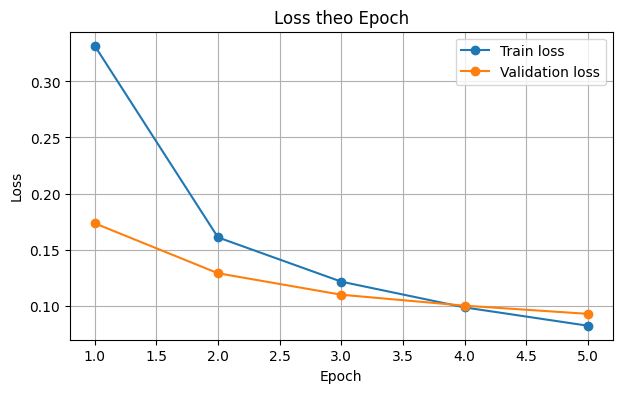

In [5]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
epochs = range(1, len(history.history["accuracy"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history["accuracy"], marker="o", label="Train accuracy")
plt.plot(epochs, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy theo Epoch")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history.history["loss"], marker="o", label="Train loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss theo Epoch")
plt.legend()
plt.grid(True)
plt.show()

## 6. Phân lớp tập test và đánh giá (câu i, j, k)

Nguyễn Đức Vinh - MSSV: 6451071087
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Test accuracy: 0.9749
              precision    recall  f1-score   support

           0     0.9818    0.9898    0.9858       980
           1     0.9834    0.9921    0.9877      1135
           2     0.9773    0.9574    0.9672      1032
           3     0.9809    0.9673    0.9741      1010
           4     0.9776    0.9776    0.9776       982
           5     0.9615    0.9787    0.9700       892
           6     0.9852    0.9729    0.9790       958
           7     0.9746    0.9708    0.9727      1028
           8     0.9508    0.9723    0.9614       974
           9     0.9741    0.9693    0.9717      1009

    accuracy                         0.9749     10000
   macro avg     0.9747    0.9748    0.9747     10000
weighted avg     0.9750    0.9749    0.9749     10000



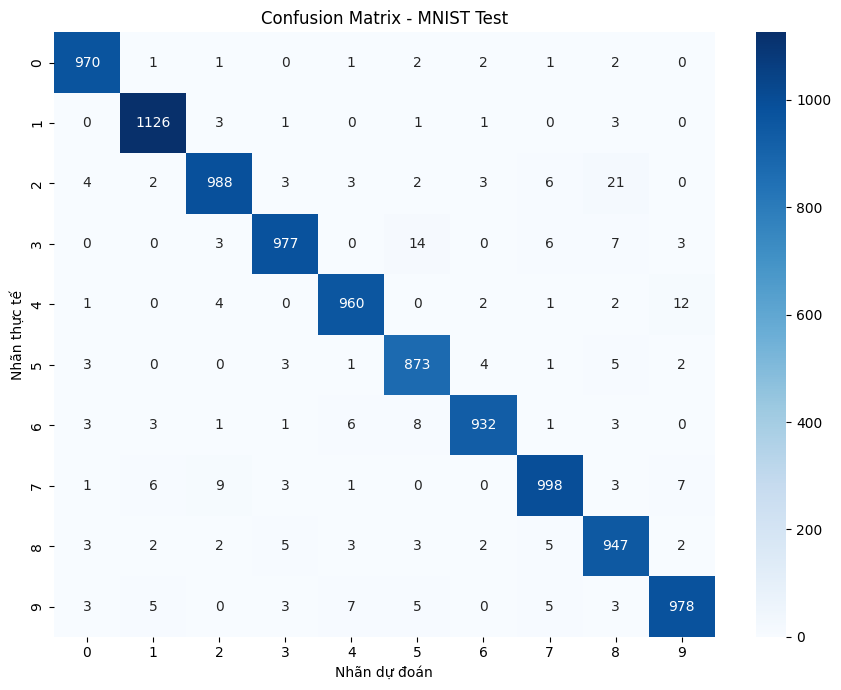

In [6]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
test_prob = model.predict(test_images, batch_size=256, verbose=1)
test_pred = np.argmax(test_prob, axis=1)
print("Test accuracy:", round(accuracy_score(test_labels, test_pred), 4))
print(classification_report(test_labels, test_pred,
                            labels=np.arange(10), digits=4, zero_division=0))
cm = confusion_matrix(test_labels, test_pred, labels=np.arange(10))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.title("Confusion Matrix - MNIST Test")
plt.tight_layout()
plt.show()

## 7. Hiển thị 05 ảnh đầu tiên (câu m)

Nguyễn Đức Vinh - MSSV: 6451071087


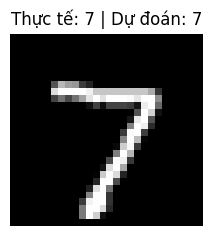

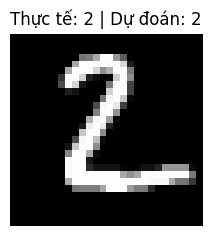

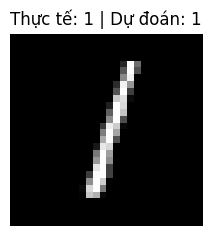

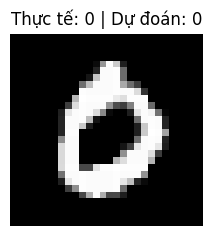

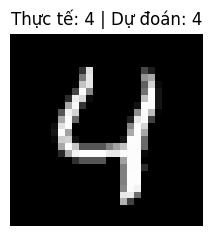

In [7]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
for index in range(5):
    image = np.expand_dims(test_images[index], axis=0)
    probabilities = model.predict(image, verbose=0)
    predicted = int(np.argmax(probabilities, axis=1)[0])
    actual = int(test_labels[index])
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(test_images[index], cmap="gray")
    plt.title(f"Thực tế: {actual} | Dự đoán: {predicted}")
    plt.axis("off")
    plt.show()

## 8. Hiển thị 05 trường hợp phân lớp sai đầu tiên (câu n)

Nguyễn Đức Vinh - MSSV: 6451071087
Các index phân lớp sai đầu tiên: [149 151 247 259 321]


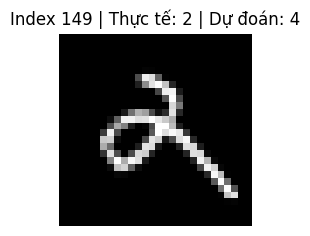

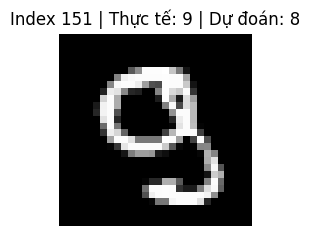

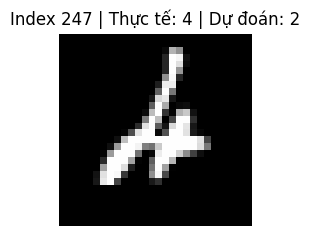

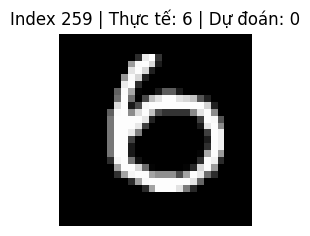

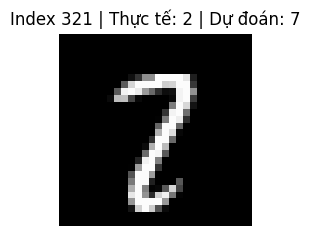

In [8]:
print("Nguyễn Đức Vinh - MSSV: 6451071087")
wrong_indices = np.where(test_pred != test_labels)[0][:5]
print("Các index phân lớp sai đầu tiên:", wrong_indices)
if len(wrong_indices) == 0:
    print("Không có mẫu phân lớp sai trong tập test.")
else:
    for index in wrong_indices:
        plt.figure(figsize=(2.5, 2.5))
        plt.imshow(test_images[index], cmap="gray")
        plt.title(f"Index {index} | Thực tế: {test_labels[index]} | Dự đoán: {test_pred[index]}")
        plt.axis("off")
        plt.show()